# **Binary Classification on make_classification**

**Goal:** 
  * separate 2 classes on noisy 2D data (`flip_y=0.07`).

**Model:** 
  * 2 hidden layers (10 units, ReLU) → 1 logit

**Loss / Optimizer:** 
  * BCEWithLogitsLoss / Adam
  
**Result:** 
  * (fill in the test accuracy after training)

In [8]:
import torch 
from torch import nn 
from sklearn.model_selection import train_test_split
from torchmetrics import Accuracy
import numpy as np


In [9]:
# Setup device agnostic code
device = "cuda" if torch.cuda.is_available() else "cpu"
device

'cpu'

In [1]:
# Create the data 
from sklearn.datasets import make_classification

X, y = make_classification(
	n_samples=1000,
	n_features=2,
	n_informative=2,
	n_redundant=0,
	flip_y=0.07,        # 7% of labels are randomly flipped (this is its "noise")
	class_sep=1.0,      # how far apart the classes are
	random_state=42
)

X[:10], y[:10]

(array([[ 0.11493126, -0.42624557],
        [ 1.92402247, -2.51781632],
        [-1.22605436, -0.35238133],
        [-1.12695239, -0.83675879],
        [-0.53260791, -0.81144947],
        [ 1.77750604,  1.79851046],
        [-1.66891959,  0.74140055],
        [-1.36714419, -0.96711139],
        [ 2.27917946,  2.35969708],
        [ 1.94436988,  2.24144923]]),
 array([1, 1, 0, 0, 0, 1, 0, 0, 1, 1]))

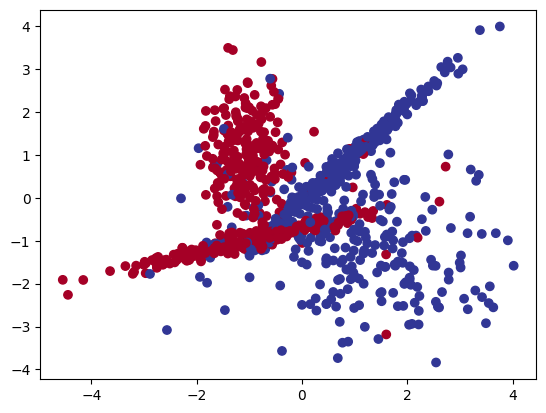

In [2]:
# Visualize the data on a plot
import matplotlib.pyplot as plt

plt.scatter(X[:, 0], X[:, 1], c=y, cmap=plt.cm.RdYlBu)
plt.show()

**Let's Split the data**

In [17]:
# Turn data into tensors
X = torch.tensor(X, dtype=torch.float)
y = torch.tensor(y, dtype=torch.float)


X_train, X_test, y_train, y_test = train_test_split(X, 
                                                    y, 
                                                    test_size=0.2, 
                                                    random_state=42)

len(X_train), len(X_test), len(y_train), len(y_test)

C:\Users\User\AppData\Local\Temp\ipykernel_25264\3957477279.py:2: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  X = torch.tensor(X, dtype=torch.float)
C:\Users\User\AppData\Local\Temp\ipykernel_25264\3957477279.py:3: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  y = torch.tensor(y, dtype=torch.float)


(800, 200, 800, 200)

**Let's build the model** 

In [18]:
class classificationModel0(nn.Module):
	def __init__(self, in_features, out_features, hidden_unites):
		super().__init__()
		self.layer_1 = nn.Linear(in_features, hidden_unites)
		self.layer_2 = nn.Linear(hidden_unites, hidden_unites)
		self.layer_3 = nn.Linear(hidden_unites, out_features)
		self.relu = nn.ReLU()

	def forward(self, x):
		x = self.layer_1(x)
		x = self.relu(x)
		x = self.layer_2(x)
		x = self.relu(x)
		x = self.layer_3(x)
		return x 


model_x = classificationModel0(in_features=2, out_features=1, hidden_unites=10)
model_x

classificationModel0(
  (layer_1): Linear(in_features=2, out_features=10, bias=True)
  (layer_2): Linear(in_features=10, out_features=10, bias=True)
  (layer_3): Linear(in_features=10, out_features=1, bias=True)
  (relu): ReLU()
)

In [19]:
# Let's check the weight and bias of the first layer

model_x.layer_1.state_dict()

OrderedDict([('weight',
              tensor([[ 0.6549,  0.1631],
                      [-0.3764, -0.4698],
                      [-0.6244, -0.3679],
                      [ 0.3803,  0.2283],
                      [-0.5627, -0.2443],
                      [-0.4247, -0.2914],
                      [-0.6387, -0.2158],
                      [ 0.5291,  0.3323],
                      [-0.5948, -0.5743],
                      [ 0.3294,  0.0923]])),
             ('bias',
              tensor([-0.4613,  0.4039,  0.3741, -0.1420,  0.0369,  0.3720,  0.5590, -0.1466,
                       0.3894, -0.0613]))])

**So now let's Create a training and testing loop to fit the model**

In [20]:
# First let's create Loss function & Optimizer 

loss_fn = nn.BCEWithLogitsLoss()
optimizer = torch.optim.SGD(params = model_x.parameters(),
							lr = 0.1
)


In [21]:
# Accuracy 
from torchmetrics import Accuracy

acc_fn = Accuracy(task= "binary").to(device)

**So before Training let's how our model_x is doing**

In [22]:
# Setup data to be device agnostic
X_train, y_train = X_train.to(device), y_train.to(device)
X_test, y_test = X_test.to(device), y_test.to(device)
print(X_train.dtype, X_test.dtype, y_train.dtype, y_test.dtype)

# Print out untrained model outputs
print("Logits:")
print(model_x(X_train)[:10])

print("Pred probs:")
print(torch.softmax(model_x(X_train)[:10], dim=1))

print("Pred labels:")
print(torch.softmax(model_x(X_train)[:10], dim=1).argmax(dim=1))

torch.float32 torch.float32 torch.float32 torch.float32
Logits:
tensor([[0.2803],
        [0.2464],
        [0.2710],
        [0.2925],
        [0.2832],
        [0.2787],
        [0.2805],
        [0.2767],
        [0.2772],
        [0.2558]], grad_fn=<SliceBackward0>)
Pred probs:
tensor([[1.],
        [1.],
        [1.],
        [1.],
        [1.],
        [1.],
        [1.],
        [1.],
        [1.],
        [1.]], grad_fn=<SoftmaxBackward0>)
Pred labels:
tensor([0, 0, 0, 0, 0, 0, 0, 0, 0, 0])


In [27]:
# Training Loop 

device = "cuda" if torch.cuda.is_available() else "cpu"

model_x = model_x.to(device)
X_train, y_train = X_train.to(device), y_train.to(device)
X_test, y_test = X_test.to(device), y_test.to(device)

torch.manual_seed(42)
epochs = 1000

for epoch in range(epochs):
	# Training 
	model_x.train()

	# Forward pass 
	y_logits = model_x(X_train).squeeze()
	y_pred_probs = torch.sigmoid(y_logits)
	y_pred_labels = torch.round(y_pred_probs)

	# Calculate the loss
	loss = loss_fn(y_logits, y_train)
	acc = acc_fn(y_pred_labels, y_train.int())

	# Zero the gradients 
	optimizer.zero_grad()

	# Loss backward 
	loss.backward()

	# Optimizer 
	optimizer.step()

	# Testing 
	model_x.eval()
	
	with torch.inference_mode():
		# Forward pass 
		test_logits = model_x(X_test).squeeze()
		test_pred = torch.round(torch.sigmoid(test_logits))

		# Calculate the loss & acc
		test_loss_x = loss_fn(test_logits, y_test)
		test_acc_x = acc_fn(test_pred, y_test.int())

	if epoch % 100 == 0 :
		print(f"Epoch: {epoch} | Loss: {loss:.2f} Acc: {acc:.2f} | Test loss: {test_loss_x:.2f} Test acc: {test_acc_x:.2f}")

Epoch: 0 | Loss: 0.68 Acc: 0.55 | Test loss: 0.69 Test acc: 0.50
Epoch: 100 | Loss: 0.39 Acc: 0.85 | Test loss: 0.45 Test acc: 0.83
Epoch: 200 | Loss: 0.36 Acc: 0.85 | Test loss: 0.45 Test acc: 0.82
Epoch: 300 | Loss: 0.36 Acc: 0.85 | Test loss: 0.45 Test acc: 0.81
Epoch: 400 | Loss: 0.36 Acc: 0.85 | Test loss: 0.45 Test acc: 0.81
Epoch: 500 | Loss: 0.36 Acc: 0.85 | Test loss: 0.45 Test acc: 0.81
Epoch: 600 | Loss: 0.36 Acc: 0.85 | Test loss: 0.45 Test acc: 0.81
Epoch: 700 | Loss: 0.36 Acc: 0.85 | Test loss: 0.45 Test acc: 0.81
Epoch: 800 | Loss: 0.36 Acc: 0.85 | Test loss: 0.45 Test acc: 0.81
Epoch: 900 | Loss: 0.36 Acc: 0.85 | Test loss: 0.45 Test acc: 0.81


In [29]:
# Plot the model predictions

import numpy as np

# TK - this could go in the helper_functions.py and be explained there
def plot_decision_boundary(model, X, y):
  
	# Put everything to CPU (works better with NumPy + Matplotlib)
	model.to("cpu")
	X, y = X.to("cpu"), y.to("cpu")

	# Source - https://madewithml.com/courses/foundations/neural-networks/ 
	# (with modifications)
	x_min, x_max = X[:, 0].min() - 0.1, X[:, 0].max() + 0.1
	y_min, y_max = X[:, 1].min() - 0.1, X[:, 1].max() + 0.1
	xx, yy = np.meshgrid(np.linspace(x_min, x_max, 101), 
						 np.linspace(y_min, y_max, 101))

	# Make features
	X_to_pred_on = torch.from_numpy(np.column_stack((xx.ravel(), yy.ravel()))).float()

	# Make predictions
	model.eval()
	with torch.inference_mode():
		y_logits = model(X_to_pred_on)

	# Test for multi-class or binary and adjust logits to prediction labels
	if len(torch.unique(y)) > 2:
		y_pred = torch.softmax(y_logits, dim=1).argmax(dim=1) # mutli-class
	else: 
		y_pred = torch.round(torch.sigmoid(y_logits)) # binary
	
	# Reshape preds and plot
	y_pred = y_pred.reshape(xx.shape).detach().numpy()
	plt.contourf(xx, yy, y_pred, cmap=plt.cm.RdYlBu, alpha=0.7)
	plt.scatter(X[:, 0], X[:, 1], c=y, s=40, cmap=plt.cm.RdYlBu)
	plt.xlim(xx.min(), xx.max())
	plt.ylim(yy.min(), yy.max())

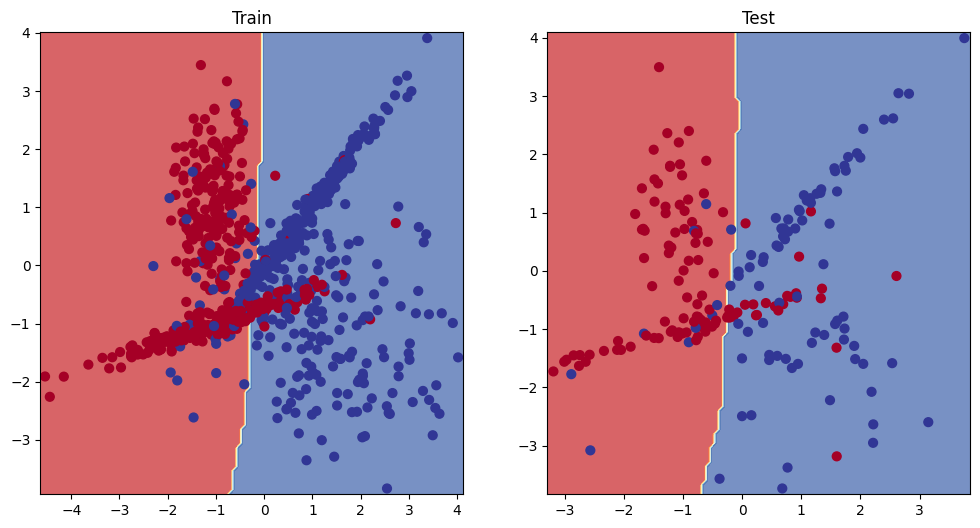

In [31]:
# Plot decision boundaries for training and test sets
plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
plt.title("Train")
plot_decision_boundary(model_x, X_train, y_train)
plt.subplot(1, 2, 2)
plt.title("Test")
plot_decision_boundary(model_x, X_test, y_test)

Why it looks like this

Look at the middle of your plot, around x between -1 and 1. There, the red streak and the blue streak overlap in the same area. Add the 7% flipped labels (the red dots deep inside blue, and the blue inside red), and a curved boundary has little to gain. If it bends to catch 3 red points in the middle, it loses 4 blue ones.

So there are two possible explanations:

 * The model is too weak (it needs more units or layers).
 * The data is the limit (the overlap and noise can’t be separated).

| Experiment | Train acc | Test acc |
|---|---|---|
| Baseline (10 units, 2 hidden layers) | 85% | 81% |
| 32 units | ? | ? |

In [32]:
from sklearn.linear_model import LogisticRegression
lr = LogisticRegression().fit(X_train.cpu(), y_train.cpu())
print(lr.score(X_test.cpu(), y_test.cpu()))

0.81


In [33]:
from sklearn.ensemble import RandomForestClassifier
rf = RandomForestClassifier(random_state=42).fit(X_train.cpu(), y_train.cpu())
print(rf.score(X_test.cpu(), y_test.cpu()))

0.88


**So let's add more Hidden Units and see how our model performe shall we :?**

In [34]:
torch.manual_seed(42)
model_x = classificationModel0(in_features=2, out_features=1, hidden_unites=64).to(device)
optimizer = torch.optim.Adam(model_x.parameters(), lr=0.01)

In [35]:
# Training Loop 

device = "cuda" if torch.cuda.is_available() else "cpu"

model_x = model_x.to(device)
X_train, y_train = X_train.to(device), y_train.to(device)
X_test, y_test = X_test.to(device), y_test.to(device)

torch.manual_seed(42)
epochs = 1000

for epoch in range(epochs):
	# Training 
	model_x.train()

	# Forward pass 
	y_logits = model_x(X_train).squeeze()
	y_pred_probs = torch.sigmoid(y_logits)
	y_pred_labels = torch.round(y_pred_probs)

	# Calculate the loss
	loss = loss_fn(y_logits, y_train)
	acc = acc_fn(y_pred_labels, y_train.int())

	# Zero the gradients 
	optimizer.zero_grad()

	# Loss backward 
	loss.backward()

	# Optimizer 
	optimizer.step()

	# Testing 
	model_x.eval()
	
	with torch.inference_mode():
		# Forward pass 
		test_logits = model_x(X_test).squeeze()
		test_pred = torch.round(torch.sigmoid(test_logits))

		# Calculate the loss & acc
		test_loss_x = loss_fn(test_logits, y_test)
		test_acc_x = acc_fn(test_pred, y_test.int())

	if epoch % 100 == 0 :
		print(f"Epoch: {epoch} | Loss: {loss:.2f} Acc: {acc:.2f} | Test loss: {test_loss_x:.2f} Test acc: {test_acc_x:.2f}")

Epoch: 0 | Loss: 0.68 Acc: 0.67 | Test loss: 0.58 Test acc: 0.80
Epoch: 100 | Loss: 0.23 Acc: 0.91 | Test loss: 0.43 Test acc: 0.88
Epoch: 200 | Loss: 0.22 Acc: 0.92 | Test loss: 0.44 Test acc: 0.88
Epoch: 300 | Loss: 0.21 Acc: 0.92 | Test loss: 0.49 Test acc: 0.88
Epoch: 400 | Loss: 0.20 Acc: 0.92 | Test loss: 0.56 Test acc: 0.89
Epoch: 500 | Loss: 0.19 Acc: 0.93 | Test loss: 0.64 Test acc: 0.89
Epoch: 600 | Loss: 0.18 Acc: 0.93 | Test loss: 0.70 Test acc: 0.89
Epoch: 700 | Loss: 0.18 Acc: 0.94 | Test loss: 0.75 Test acc: 0.89
Epoch: 800 | Loss: 0.18 Acc: 0.93 | Test loss: 0.81 Test acc: 0.88
Epoch: 900 | Loss: 0.17 Acc: 0.93 | Test loss: 0.88 Test acc: 0.88


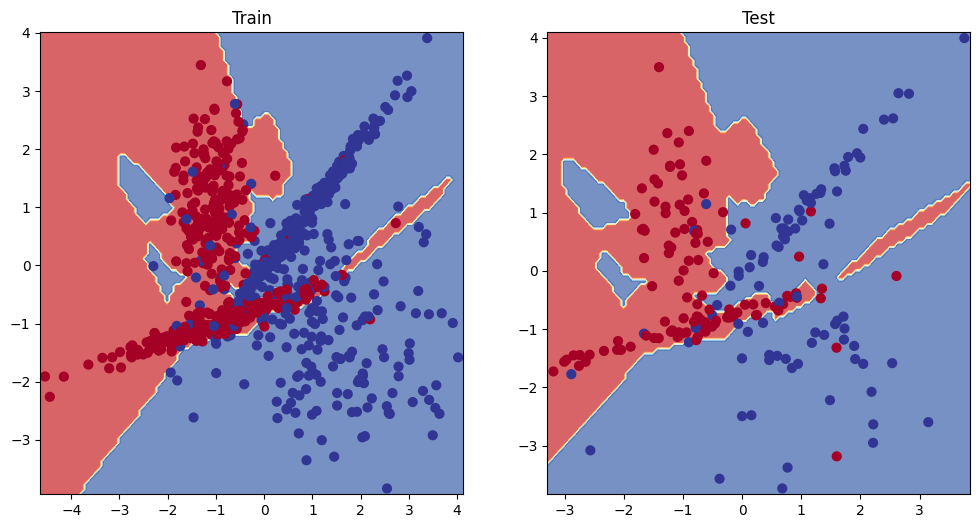

In [36]:
plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
plt.title("Train")
plot_decision_boundary(model_x, X_train, y_train)
plt.subplot(1, 2, 2)
plt.title("Test")
plot_decision_boundary(model_x, X_test, y_test)



We can see that increasing the number of hidden units to `64` and using the Adam optimizer with a learning rate of `0.01` improved the test accuracy from around `80%` to `88–89%`.

However, the training loss keeps decreasing while the test loss increases from `0.43` to `0.88`. This suggests that the model may be overfitting, learning the training data better without improving its generalization to unseen data.

Let's try reducing the learning rate to `0.001` and using fewer hidden units to investigate whether we can achieve more stable training and better generalization.

In [38]:

torch.manual_seed(42)

model_x = classificationModel0(
    in_features=2,
    out_features=1,
    hidden_unites=10
).to(device)

loss_fn = nn.BCEWithLogitsLoss()

optimizer = torch.optim.Adam(
    model_x.parameters(),
    lr=0.001
)


In [39]:
# Training Loop 

device = "cuda" if torch.cuda.is_available() else "cpu"

model_x = model_x.to(device)
X_train, y_train = X_train.to(device), y_train.to(device)
X_test, y_test = X_test.to(device), y_test.to(device)

torch.manual_seed(42)
epochs = 1000

for epoch in range(epochs):
	# Training 
	model_x.train()

	# Forward pass 
	y_logits = model_x(X_train).squeeze()
	y_pred_probs = torch.sigmoid(y_logits)
	y_pred_labels = torch.round(y_pred_probs)

	# Calculate the loss
	loss = loss_fn(y_logits, y_train)
	acc = acc_fn(y_pred_labels, y_train.int())

	# Zero the gradients 
	optimizer.zero_grad()

	# Loss backward 
	loss.backward()

	# Optimizer 
	optimizer.step()

	# Testing 
	model_x.eval()
	
	with torch.inference_mode():
		# Forward pass 
		test_logits = model_x(X_test).squeeze()
		test_pred = torch.round(torch.sigmoid(test_logits))

		# Calculate the loss & acc
		test_loss_x = loss_fn(test_logits, y_test)
		test_acc_x = acc_fn(test_pred, y_test.int())

	if epoch % 100 == 0 :
		print(f"Epoch: {epoch} | Loss: {loss:.2f} Acc: {acc:.2f} | Test loss: {test_loss_x:.2f} Test acc: {test_acc_x:.2f}")

Epoch: 0 | Loss: 0.69 Acc: 0.54 | Test loss: 0.69 Test acc: 0.49
Epoch: 100 | Loss: 0.56 Acc: 0.83 | Test loss: 0.57 Test acc: 0.82
Epoch: 200 | Loss: 0.40 Acc: 0.84 | Test loss: 0.45 Test acc: 0.83
Epoch: 300 | Loss: 0.36 Acc: 0.85 | Test loss: 0.44 Test acc: 0.83
Epoch: 400 | Loss: 0.35 Acc: 0.85 | Test loss: 0.43 Test acc: 0.83
Epoch: 500 | Loss: 0.34 Acc: 0.86 | Test loss: 0.42 Test acc: 0.84
Epoch: 600 | Loss: 0.33 Acc: 0.87 | Test loss: 0.40 Test acc: 0.85
Epoch: 700 | Loss: 0.31 Acc: 0.87 | Test loss: 0.38 Test acc: 0.86
Epoch: 800 | Loss: 0.30 Acc: 0.88 | Test loss: 0.37 Test acc: 0.85
Epoch: 900 | Loss: 0.29 Acc: 0.89 | Test loss: 0.36 Test acc: 0.87


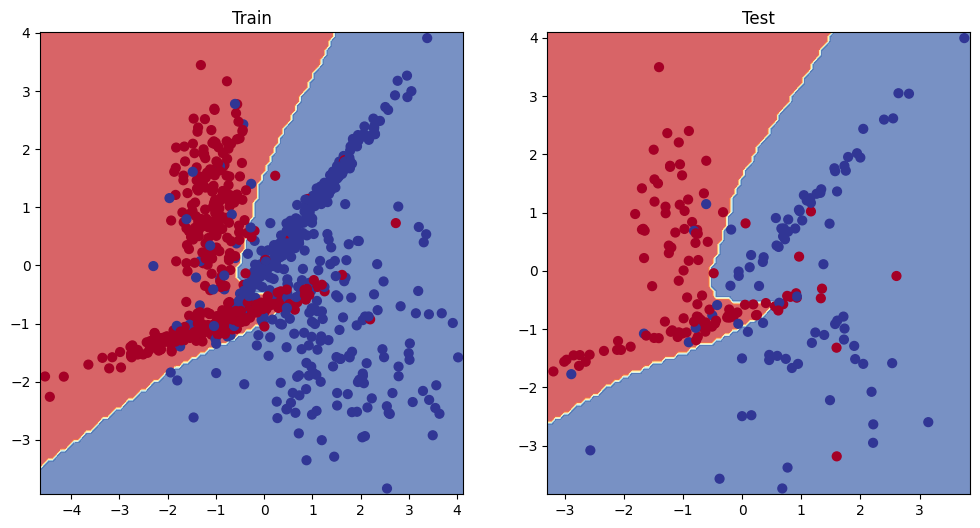

In [40]:
plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
plt.title("Train")
plot_decision_boundary(model_x, X_train, y_train)
plt.subplot(1, 2, 2)
plt.title("Test")
plot_decision_boundary(model_x, X_test, y_test)

We can see that our model is learning progressively, with the training loss decreasing from `0.69` to `0.29` and the test loss decreasing from `0.69` to `0.36`. The test accuracy has improved from around `49%` to `85–87%`.

Let's increase the number of hidden units from `10` to `32` while keeping the same optimizer (`Adam`), learning rate (`0.001`), and dataset.

By doing this, we want to investigate whether increasing the model's capacity helps it learn better decision boundaries and improve its performance on unseen data.

In [42]:
torch.manual_seed(42)

model_x = classificationModel0(
    in_features=2,
    out_features=1,
    hidden_unites=32
).to(device)

loss_fn = nn.BCEWithLogitsLoss()

optimizer = torch.optim.Adam(
    params=model_x.parameters(),
    lr=0.001
)

In [43]:
# Training Loop 

device = "cuda" if torch.cuda.is_available() else "cpu"

model_x = model_x.to(device)
X_train, y_train = X_train.to(device), y_train.to(device)
X_test, y_test = X_test.to(device), y_test.to(device)

torch.manual_seed(42)
epochs = 1000

for epoch in range(epochs):
	# Training 
	model_x.train()

	# Forward pass 
	y_logits = model_x(X_train).squeeze()
	y_pred_probs = torch.sigmoid(y_logits)
	y_pred_labels = torch.round(y_pred_probs)

	# Calculate the loss
	loss = loss_fn(y_logits, y_train)
	acc = acc_fn(y_pred_labels, y_train.int())

	# Zero the gradients 
	optimizer.zero_grad()

	# Loss backward 
	loss.backward()

	# Optimizer 
	optimizer.step()

	# Testing 
	model_x.eval()
	
	with torch.inference_mode():
		# Forward pass 
		test_logits = model_x(X_test).squeeze()
		test_pred = torch.round(torch.sigmoid(test_logits))

		# Calculate the loss & acc
		test_loss_x = loss_fn(test_logits, y_test)
		test_acc_x = acc_fn(test_pred, y_test.int())

	if epoch % 100 == 0 :
		print(f"Epoch: {epoch} | Loss: {loss:.2f} Acc: {acc:.2f} | Test loss: {test_loss_x:.2f} Test acc: {test_acc_x:.2f}")

Epoch: 0 | Loss: 0.70 Acc: 0.38 | Test loss: 0.69 Test acc: 0.49
Epoch: 100 | Loss: 0.36 Acc: 0.86 | Test loss: 0.44 Test acc: 0.81
Epoch: 200 | Loss: 0.33 Acc: 0.87 | Test loss: 0.41 Test acc: 0.85
Epoch: 300 | Loss: 0.31 Acc: 0.88 | Test loss: 0.38 Test acc: 0.85
Epoch: 400 | Loss: 0.29 Acc: 0.89 | Test loss: 0.37 Test acc: 0.87
Epoch: 500 | Loss: 0.27 Acc: 0.90 | Test loss: 0.37 Test acc: 0.88
Epoch: 600 | Loss: 0.25 Acc: 0.90 | Test loss: 0.39 Test acc: 0.87
Epoch: 700 | Loss: 0.25 Acc: 0.90 | Test loss: 0.40 Test acc: 0.88
Epoch: 800 | Loss: 0.24 Acc: 0.91 | Test loss: 0.41 Test acc: 0.88
Epoch: 900 | Loss: 0.24 Acc: 0.91 | Test loss: 0.42 Test acc: 0.88


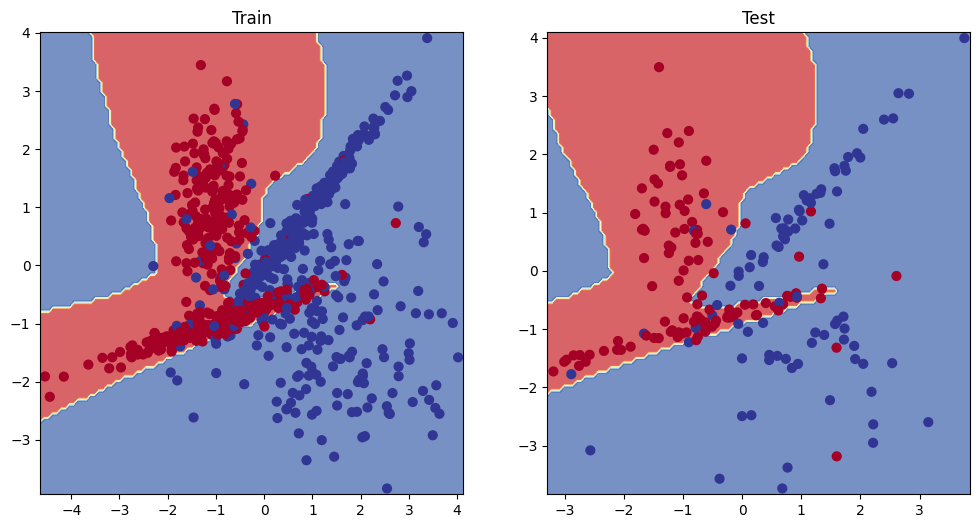

In [44]:
plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
plt.title("Train")
plot_decision_boundary(model_x, X_train, y_train)
plt.subplot(1, 2, 2)
plt.title("Test")
plot_decision_boundary(model_x, X_test, y_test)